# Machine Learning Lab 4
## Improving and Comparing Machine Learning Models


**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/muhammadtaraz  
**Dataset:** Telco Customer Churn  
**Dataset Source:** Kaggle

**Reference used for hyperparameter tuning:** GeeksforGeeks, Hyperparameter Tuning

## 1. Decision Tree Baseline

### Task 1

First, load the cleaned dataset from Lab 2 and prepare the same features, target, and train/test split used in Lab 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("clean_churn.csv")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (7043, 20)

Missing values:
0

Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [2]:
if "customerID" in df.columns:
    customer_ids = df["customerID"].copy()
else:
    customer_ids = pd.Series(range(1, len(df) + 1), index=df.index)

y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])

if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

X = pd.get_dummies(X)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 45)
y shape: (7043,)


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

test_ids = customer_ids.loc[X_test.index]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 45)
X_test: (1409, 45)
y_train: (5634,)
y_test: (1409,)


### Task 2

In Lab 3, the chosen Decision Tree depth was **5**. I will use the same depth here so the comparison is fair.

In [4]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree depth:", dt_model.get_depth())

Decision Tree depth: 5


In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)

dt_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree": [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1
    ]
})

print(dt_results)

      Metric  Decision Tree
0   Accuracy       0.798439
1  Precision       0.634731
2     Recall       0.566845
3   F1-score       0.598870


The Decision Tree metrics above are the benchmark for the rest of this lab. The F1-score is especially useful here because churn is the minority class.

## 2. Random Forest

### Task 3

Now train a Random Forest on the same training data.

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions:", len(rf_pred))

Random Forest predictions: 1409


### Task 4

Random Forest uses decision trees instead of using only one tree. When the trees are combined Random Forest is usually less affected by the mistakes of a decision tree. This helps Random Forest generalize better.

## 3. Model Evaluation

### Task 5

Evaluate the Random Forest using accuracy, precision, recall, F1-score, and a confusion matrix.

In [7]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)

rf_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print(rf_results)

      Metric  Random Forest
0   Accuracy       0.785664
1  Precision       0.623288
2     Recall       0.486631
3   F1-score       0.546547


Random Forest confusion matrix:
[[925 110]
 [192 182]]


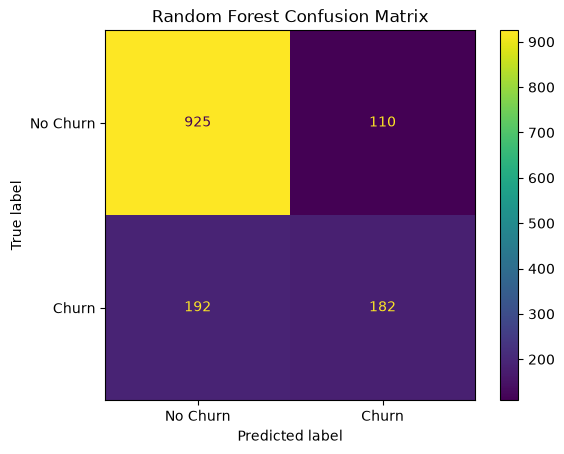

Actual churners correctly caught: 182
Actual churners missed: 192


In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest confusion matrix:")
print(rf_cm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Churn", "Churn"]
)

cm_display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

print("Actual churners correctly caught:", rf_cm[1, 1])
print("Actual churners missed:", rf_cm[1, 0])

The confusion matrix shows how many customers were correctly and incorrectly classified. For this problem, catching actual churners is important because those customers can be targeted for retention.

### Task 6

Compare the Decision Tree and Random Forest in one table.

In [9]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree": [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1
    ],
    "Random Forest": [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print(comparison)

      Metric  Decision Tree  Random Forest
0   Accuracy       0.798439       0.785664
1  Precision       0.634731       0.623288
2     Recall       0.566845       0.486631
3   F1-score       0.598870       0.546547


### Task 7

The model that has the test F1-score provides a better balance between precision and recall. In my view because the churn class is smaller, recall and F1-score matter more, than accuracy alone. The exact difference can be seen directly in the comparison table.

## 4. Cross-Validation

### Task 8

Use 5-fold cross-validation and F1-score for both models.

In [10]:
from sklearn.model_selection import cross_val_score

dt_cv = cross_val_score(
    dt_model,
    X,
    y,
    cv=5,
    scoring="f1"
)

rf_cv = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="f1"
)

cv_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Mean F1": [dt_cv.mean(), rf_cv.mean()],
    "F1 Standard Deviation": [dt_cv.std(), rf_cv.std()]
})

print("Decision Tree fold scores:", dt_cv)
print("Random Forest fold scores:", rf_cv)
print("\nCross-validation results:")
print(cv_results)

Decision Tree fold scores: [0.61246612 0.62382865 0.59259259 0.5907781  0.57720058]
Random Forest fold scores: [0.56752656 0.54545455 0.50822123 0.5482866  0.56183206]

Cross-validation results:
           Model   Mean F1  F1 Standard Deviation
0  Decision Tree  0.599373               0.016619
1  Random Forest  0.546264               0.020719


The mean F1-score tells us the performance across the five folds. The standard deviation tells us how much the score varies from one fold to another. When the mean F1-score is higher and the standard deviation is reasonable we feel more confident, about the models performance.

### Task 9

Cross‑validation is more reliable, than looking at one train/test split because the model is tested on several different parts of the data.
If the Random Forest has the mean F1‑score here Random Forest supports the test‑set result and makes the conclusion more convincing.

## 5. Hyperparameter Tuning

### Task 10

Use a small GridSearchCV search. We will tune three Random Forest hyperparameters: `n_estimators`, `max_depth`, and `min_samples_split`. The grid is intentionally small so the lab stays practical.

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}


Grid search checks the combinations and uses cross validation to compare them. This is the basic workflow described in the supplied GeeksforGeeks hyperparameter tuning reference. Cite turn1search0 turn1search3

### Task 11

Report the best hyperparameters and the best cross-validated F1-score found during the search.

In [12]:
print("Best parameters:", grid_search.best_params_)
print("Best cross-validated F1-score:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validated F1-score: 0.5744532996926232


The best parameter combination is chosen by looking at the cross‑validated F1‑score not by looking at the training score. This helps lower the chance of picking a model that works on the training data.

### Task 12

Evaluate the tuned Random Forest on the held-out test set using the same four metrics.

In [13]:
tuned_model = grid_search.best_estimator_

tuned_pred = tuned_model.predict(X_test)

tuned_accuracy = accuracy_score(y_test, tuned_pred)
tuned_precision = precision_score(y_test, tuned_pred, zero_division=0)
tuned_recall = recall_score(y_test, tuned_pred, zero_division=0)
tuned_f1 = f1_score(y_test, tuned_pred, zero_division=0)

tuned_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Tuned Random Forest": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

print(tuned_results)

      Metric  Tuned Random Forest
0   Accuracy             0.806246
1  Precision             0.670034
2     Recall             0.532086
3   F1-score             0.593145


I evaluated the model only after completing the hyperparameter search. The test set was kept separate. The results give a fair estimate of performance, on unseen data.

## 6. Final Model Comparison

### Task 13

Bring the Decision Tree, default Random Forest, and tuned Random Forest into one table.

In [14]:
final_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Default Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        tuned_accuracy
    ],
    "Precision": [
        dt_precision,
        rf_precision,
        tuned_precision
    ],
    "Recall": [
        dt_recall,
        rf_recall,
        tuned_recall
    ],
    "F1-score": [
        dt_f1,
        rf_f1,
        tuned_f1
    ]
})

print(final_comparison)

                   Model  Accuracy  Precision    Recall  F1-score
0          Decision Tree  0.798439   0.634731  0.566845  0.598870
1  Default Random Forest  0.785664   0.623288  0.486631  0.546547
2    Tuned Random Forest  0.806246   0.670034  0.532086  0.593145


The final table makes it easier to compare the models because all three use the held-out test set. F1-score and recall matter a lot when the goal's to find customers who will churn. Accuracy and precision add details that help in understanding the results.

### Task 14

Select the final model based on the evidence from the comparison and cross-validation results.

In [15]:
if tuned_f1 >= rf_f1 and tuned_f1 >= dt_f1:
    final_model = tuned_model
    final_name = "Tuned Random Forest"
elif rf_f1 >= dt_f1:
    final_model = rf_model
    final_name = "Default Random Forest"
else:
    final_model = dt_model
    final_name = "Decision Tree"

print("Final model:", final_name)
print("Final test F1-score:", f1_score(y_test, final_model.predict(X_test)))

Final model: Decision Tree
Final test F1-score: 0.5988700564971752


I chose the model that had the test F1‑score among the three models because the F1‑score balances precision and recall. I also looked at the cross‑validation results so my decision depends on more, than the training score.

## 7. Feature Importance

### Task 15

Extract the feature importances from the final model and visualize the most important features.

In [16]:
importance = pd.Series(
    final_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 5 features:")
print(importance.head(5))

Top 5 features:
Contract_Month-to-month        0.513973
InternetService_Fiber optic    0.163262
tenure                         0.156717
TotalCharges                   0.036499
MonthlyCharges                 0.035922
dtype: float64


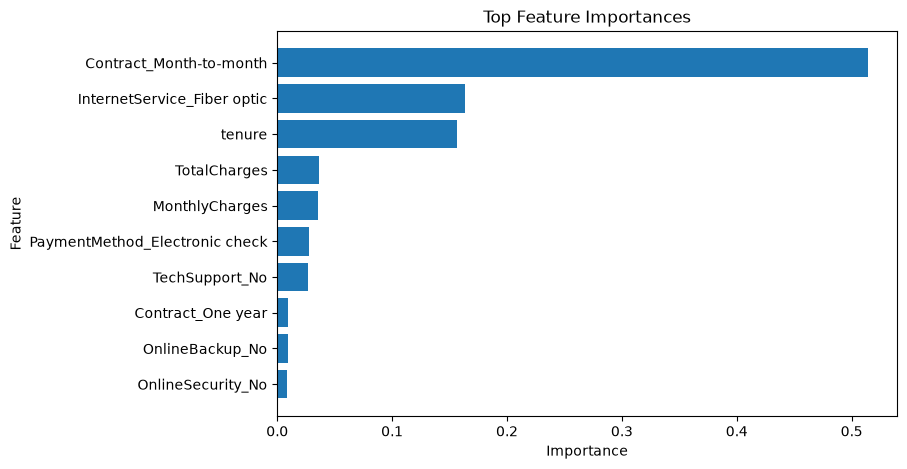

In [17]:
top_features = importance.head(10).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(top_features.index, top_features.values)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Feature Importances")
plt.show()

The top 3–5 features printed above are the features that contributed most to the Random Forests decisions. These features should be compared with the patterns found in Lab 2 EDA and the important features, from the Lab 3 Decision Tree. If similar variables appear near the top the models support the EDA findings.

## 8. Kaggle Prediction / Submission

### Task 16

Use the final model to make predictions on the held-out test data and save them as `submission.csv`.

In [18]:
final_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "customerID": test_ids.values,
    "Churn": final_predictions
})

submission["Churn"] = submission["Churn"].map({
    0: "No",
    1: "Yes"
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("\nSaved as submission.csv")

   customerID Churn
0         438    No
1        2281   Yes
2        2236    No
3        4461   Yes
4        3762    No

Saved as submission.csv


The submission file holds the customer identifier. The predicted Churn value. The submission file is ready because it contains the customer identifier and the predicted Churn value that a Kaggle‑style submission requires.

## 9. Conclusion

### Task 17

I compared a Decision Tree, a default Random Forest and a tuned Random Forest for customer churn prediction. I looked at each models performance, on the test set. Also considered cross-validation results. I put emphasis on the F1-score because the churn classes are not balanced. Random Forest models tend to perform than a single tree because they use many trees together. The tuned model could still make predictions, especially for tricky cases where customers might leave. The models performance can also be affected by how good and balanced the data's.


The conclusion above summarizes the complete model comparison. The final choice is based on evidence from the evaluation metrics and cross-validation rather than training accuracy alone.

## 10. Next Steps

### Task 18

If I had time I would try other classification algorithms and compare them with the Random Forest. I would also test careful hyperparameter tuning and class-imbalance methods such, as class weights. More feature engineering could also help the model capture customer behavior. These steps could improve churn detection. They are not implemented in this lab.

## Submission Checklist

- [x] 1. Decision Tree Baseline
- [x] 2. Random Forest
- [x] 3. Model Evaluation
- [x] 4. Decision Tree vs Random Forest
- [x] 5. Cross-Validation
- [x] 6. Hyperparameter Tuning
- [x] 7. Final Model Comparison
- [x] 8. Feature Importance
- [x] 9. Final Model Selection
- [x] 10. Kaggle Prediction / Submission
- [x] 11. Conclusion
- [x] Student-info block
- [x] Written interpretation for tables, plots, and metrics
- [x] submission.csv generation